# Task 1: Compare SVM with Previous Classifiers
**SalaryInsight: Predictive Modeling for Informed Salary Predictions**

Goal: evaluate the trade-off between interpretability and accuracy, analyse misclassification trends, and choose the best model for deployment.

*Salary_LPA is converted into 3 equal-sized salary bands (Low / Medium / High) so this becomes a classification problem.*

In [1]:
import numpy as np, pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

RS = 42
LABELS = ["Low", "Medium", "High"]
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

## 1. Load data and create salary bands

In [2]:
df = pd.read_csv("employee_data.csv")
df["Salary_Band"] = pd.qcut(df["Salary_LPA"], 3, labels=LABELS)
print(df.shape); print(df.isna().sum()[lambda s: s > 0])
df["Salary_Band"].value_counts()

(2000, 13)
Performance_Rating    25
Training_Hours        25
dtype: int64


Salary_Band
Low       668
High      667
Medium    665
Name: count, dtype: int64

## 2. Preprocessing and train/test split
Missing values are median-imputed, numeric features scaled, categorical features one-hot encoded.

In [3]:
X, y = df.drop(columns=["Salary_LPA", "Salary_Band"]), df["Salary_Band"]
num = X.select_dtypes("number").columns.tolist()
cat = [c for c in X.columns if c not in num]

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
cv = StratifiedKFold(5, shuffle=True, random_state=RS)

## 3. Train and compare classifiers

In [4]:
from sklearn.model_selection import cross_val_score

models = {   # (model, interpretability level)
    "Logistic Regression": (LogisticRegression(max_iter=2000), "High"),
    "Decision Tree":       (DecisionTreeClassifier(max_depth=5, random_state=RS), "High"),
    "KNN":                 (KNeighborsClassifier(n_neighbors=15), "Medium"),
    "Random Forest":       (RandomForestClassifier(n_estimators=300, random_state=RS), "Low"),
    "SVM (RBF)":           (SVC(kernel="rbf", C=1, random_state=RS), "Low"),
}
rows, cms = [], {}
for name, (clf, interp) in models.items():
    pipe = Pipeline([("pre", pre), ("clf", clf)])
    cvs = cross_val_score(pipe, Xtr, ytr, cv=cv, scoring="accuracy")
    pipe.fit(Xtr, ytr); p = pipe.predict(Xte)
    cm = confusion_matrix(yte, p, labels=LABELS); cms[name] = cm
    rows.append({"Model": name, "Interpretability": interp,
                 "CV Acc": round(cvs.mean(), 4), "CV Std": round(cvs.std(), 4),
                 "Test Acc": round(accuracy_score(yte, p), 4),
                 "Test F1 (macro)": round(f1_score(yte, p, average="macro"), 4)})
results = pd.DataFrame(rows).sort_values("CV Acc", ascending=False).reset_index(drop=True)
results

,Model,Interpretability,CV Acc,CV Std,Test Acc,Test F1 (macro)
0,Logistic Regression,High,0.8587,0.0186,0.8750,0.8757
1,SVM (RBF),Low,0.8506,0.0250,0.8400,0.8409
2,Random Forest,Low,0.8081,0.0192,0.8325,0.8325
3,KNN,Medium,0.7431,0.0308,0.7275,0.7236
4,Decision Tree,High,0.7288,0.0114,0.7375,0.7370


## 4. Misclassification analysis
Rows = actual band, columns = predicted band. *Adjacent* errors (e.g. Low→Medium) are mild; *severe* errors (Low↔High) are costly.

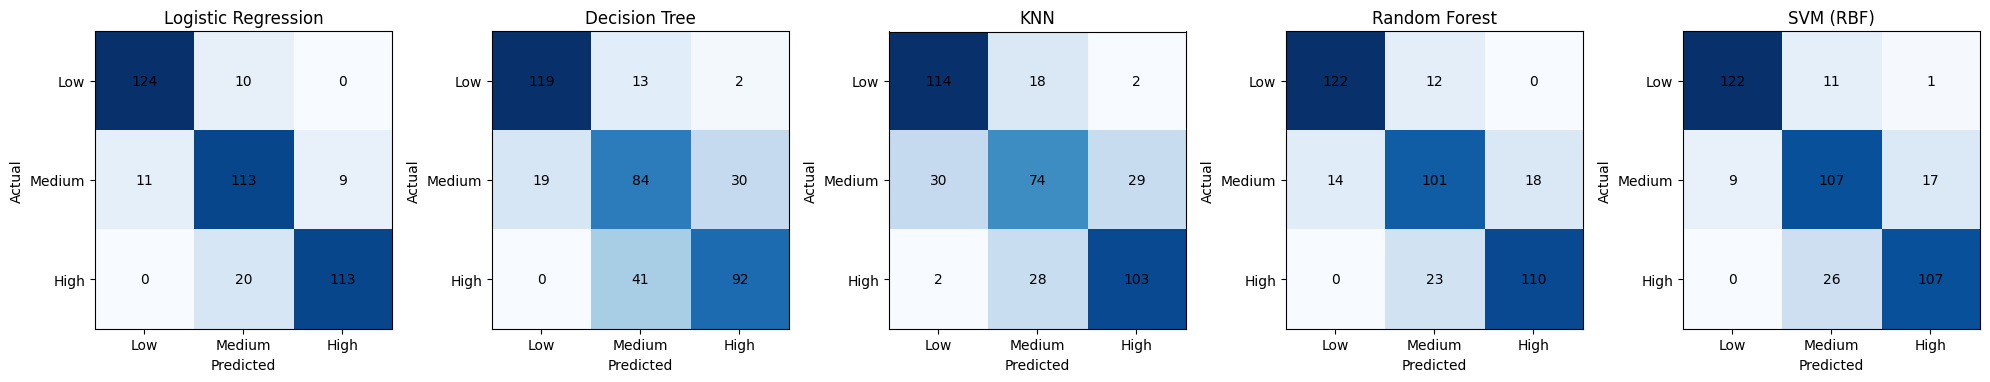

,Model,Adjacent errors,Severe errors (Low<->High),Total errors
0,Logistic Regression,50,0,50
4,SVM (RBF),63,1,64
3,Random Forest,67,0,67
1,Decision Tree,103,2,105
2,KNN,105,4,109


In [5]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, (n, cm) in zip(axes, cms.items()):
    ax.imshow(cm, cmap="Blues")
    ax.set_title(n); ax.set_xticks(range(3)); ax.set_xticklabels(LABELS)
    ax.set_yticks(range(3)); ax.set_yticklabels(LABELS)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="black")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

err = []
for n, cm in cms.items():
    far = cm[0,2] + cm[2,0]; adj = cm[0,1] + cm[1,0] + cm[1,2] + cm[2,1]
    err.append({"Model": n, "Adjacent errors": adj, "Severe errors (Low<->High)": far, "Total errors": adj + far})
pd.DataFrame(err).sort_values("Total errors")

In [6]:
svm = Pipeline([("pre", pre), ("clf", models["SVM (RBF)"][0])]).fit(Xtr, ytr)
print(classification_report(yte, svm.predict(Xte), labels=LABELS))

              precision    recall  f1-score   support

         Low       0.93      0.91      0.92       134
      Medium       0.74      0.80      0.77       133
        High       0.86      0.80      0.83       133

    accuracy                           0.84       400
   macro avg       0.84      0.84      0.84       400
weighted avg       0.84      0.84      0.84       400



## 5. Accuracy vs interpretability and model choice

- **Logistic Regression** is both the most interpretable *and* the most accurate at default settings (CV 0.859, test 0.875) with zero severe errors. Salary here depends on near-linear effects (experience, education, department).
- **SVM (RBF)** is close behind (CV 0.851, test 0.840) but is a black box, so it loses on interpretability.
- **Random Forest** is less accurate (0.81) and harder to explain; **KNN** and **Decision Tree** are clearly weaker (~0.73-0.74) with more errors and more severe errors.
- Almost all mistakes are between neighbouring bands, and **Medium** is the hardest band to predict.

**Decision:** at default settings Logistic Regression is the best trade-off. SVM is the strongest non-linear candidate and is tuned in Task 2 to see if it can overtake it.